# PortalPulse Module 1 — EDA

Team 1 analysis of the **single master table** handed to Team 2.

This notebook does **not** split train / validation / test and does **not** train a model.
It answers: *does this table actually contain a workload → performance → capacity relationship?*

**Data file:** `dataset_clean.csv` (same folder as this notebook, or `../processed/`).


## 0. Load

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 110

candidates = [
    Path("dataset_clean.csv"),
    Path("../processed/dataset_clean.csv"),
    Path("team1_work/processed/dataset_clean.csv"),
    Path("/home/pratay-karali/Desktop/portalpulse/team1_work/processed/dataset_clean.csv"),
]
data_path = next(p for p in candidates if p.exists())
print("loading", data_path.resolve())

df = pd.read_csv(data_path, parse_dates=["timestamp"])
print(df.shape)
df.head()


loading /home/pratay-karali/Desktop/portalpulse/team1_work/processed/dataset_clean.csv
(39584, 14)


,timestamp,hour,day_of_week,is_weekend,is_result_window,concurrent_users,requests_per_sec,cpu_usage,memory_usage,network_usage,latency_ms,error_rate,safe_capacity,risk_level
0,2025-06-16 00:00:00,0,0,0,0,3655,419.615,40.94,31.94,18.20,88.9,0.00148,7774,SAFE
1,2025-06-16 00:01:00,0,0,0,0,4124,486.353,39.93,35.48,19.51,71.7,0.00150,8139,SAFE
2,2025-06-16 00:02:00,0,0,0,0,4225,493.275,41.37,34.06,22.50,49.9,0.00073,7775,SAFE
3,2025-06-16 00:03:00,0,0,0,0,4761,567.810,49.02,33.39,26.96,78.3,0.00136,7662,SAFE
4,2025-06-16 00:04:00,0,0,0,0,4850,567.630,40.64,37.30,23.64,45.8,0.00000,8510,SAFE


## 1. Shape, types, missing values, duplicates

What we need before trusting any plot.


In [2]:
print("rows, cols:", df.shape)
print("time range:", df["timestamp"].min(), "→", df["timestamp"].max())
print("unique timestamps:", df["timestamp"].nunique())
print()
df.info()
print()
print("missing values")
print(df.isnull().sum())
print()
print("duplicate rows:", int(df.duplicated().sum()))
print("duplicate timestamps:", int(df["timestamp"].duplicated().sum()))


rows, cols: (39584, 14)
time range: 2025-06-16 00:00:00 → 2025-07-13 13:32:00
unique timestamps: 39584

<class 'pandas.DataFrame'>
RangeIndex: 39584 entries, 0 to 39583
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   timestamp         39584 non-null  datetime64[us]
 1   hour              39584 non-null  int64         
 2   day_of_week       39584 non-null  int64         
 3   is_weekend        39584 non-null  int64         
 4   is_result_window  39584 non-null  int64         
 5   concurrent_users  39584 non-null  int64         
 6   requests_per_sec  39584 non-null  float64       
 7   cpu_usage         39584 non-null  float64       
 8   memory_usage      39584 non-null  float64       
 9   network_usage     39584 non-null  float64       
 10  latency_ms        39584 non-null  float64       
 11  error_rate        39584 non-null  float64       
 12  safe_capacity     39584 non-null  int

In [3]:
df.describe().T


,count,mean,min,25%,50%,75%,max,std
timestamp,39584,2025-06-29 18:46:14.766572,2025-06-16 00:00:00,2025-06-22 21:22:45,2025-06-29 18:43:30,2025-07-06 16:07:15,2025-07-13 13:32:00,NaN
hour,39584.0,11.392886,0.0,5.0,11.0,17.0,23.0,6.913467
day_of_week,39584.0,2.953517,0.0,1.0,3.0,5.0,6.0,1.979587
is_weekend,39584.0,0.274581,0.0,0.0,0.0,1.0,1.0,0.446308
is_result_window,39584.0,0.108731,0.0,0.0,0.0,0.0,1.0,0.311305
concurrent_users,39584.0,2942.760434,56.0,1614.75,2583.0,3879.0,12500.0,1815.160889
requests_per_sec,39584.0,352.603546,5.599,194.169,308.7075,465.69375,1769.348,219.438775
cpu_usage,39584.0,38.758865,3.3,25.1,33.435,47.66,100.0,19.056591
memory_usage,39584.0,31.822626,13.93,26.59,30.1,35.5,75.5,7.494591
network_usage,39584.0,15.401491,0.0,8.2,13.21,20.18,84.47,10.353253


## 2. What each column is

| Column | Role |
|---|---|
| `timestamp` | minute of observation |
| `hour`, `day_of_week`, `is_weekend`, `is_result_window` | calendar features |
| `concurrent_users`, `requests_per_sec` | traffic / workload |
| `cpu_usage`, `memory_usage`, `network_usage` | server metrics |
| `latency_ms`, `error_rate` | performance |
| `safe_capacity` | **primary target (regression)** |
| `risk_level` | **derived target (classification)** |

`risk_level` is computed from utilization = `concurrent_users / safe_capacity` and from SLA breaches. Team 2 can train either or both. Do **not** feed `safe_capacity` in as a feature if the task is to predict it.


## 3. Target distributions

In [4]:
print(df["risk_level"].value_counts())
print()
print(df["risk_level"].value_counts(normalize=True).round(3))
print()
print("safe_capacity")
print(df["safe_capacity"].describe().round(1))


risk_level
SAFE          33294
AT_RISK        3156
OVERLOADED     3134
Name: count, dtype: int64

risk_level
SAFE          0.841
AT_RISK       0.080
OVERLOADED    0.079
Name: proportion, dtype: float64

safe_capacity
count    39584.0
mean      7046.6
std       1048.3
min       3626.0
25%       6729.0
50%       7231.0
75%       7776.0
max       9248.0
Name: safe_capacity, dtype: float64


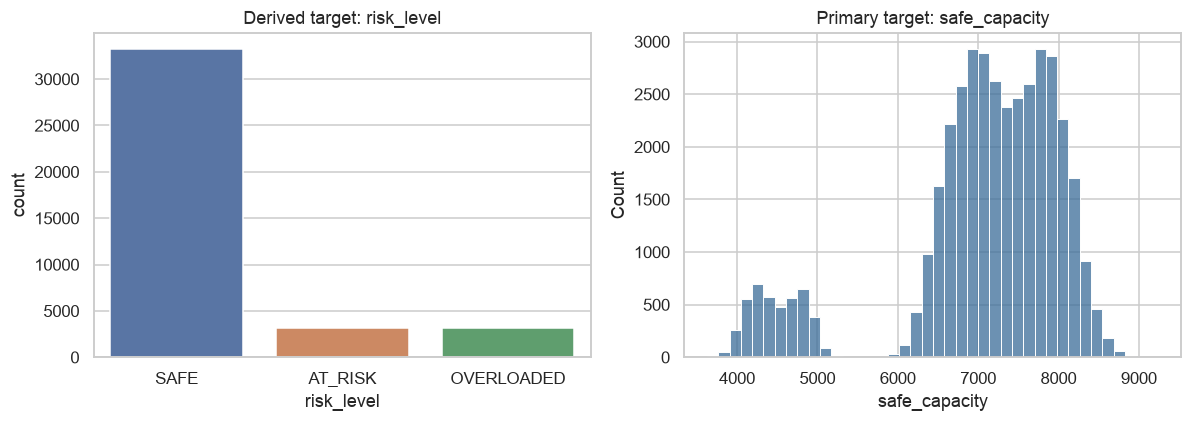

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = ["SAFE", "AT_RISK", "OVERLOADED"]
sns.countplot(data=df, x="risk_level", order=order, ax=axes[0], hue="risk_level", hue_order=order, legend=False)
axes[0].set_title("Derived target: risk_level")
sns.histplot(df["safe_capacity"], bins=40, ax=axes[1], color="#3b6d99")
axes[1].set_title("Primary target: safe_capacity")
fig.tight_layout()
plt.show()


SAFE is the majority class (~84%). That is expected: most minutes of a month are ordinary office-hour or night traffic. The minority classes are the minutes that matter on result day.

If Team 2 trains a classifier, they should **not** use raw accuracy as the only metric. Use macro-F1 / recall on `OVERLOADED`. False negatives (calling an overloaded minute SAFE) are the expensive error.


## 4. Feature distributions

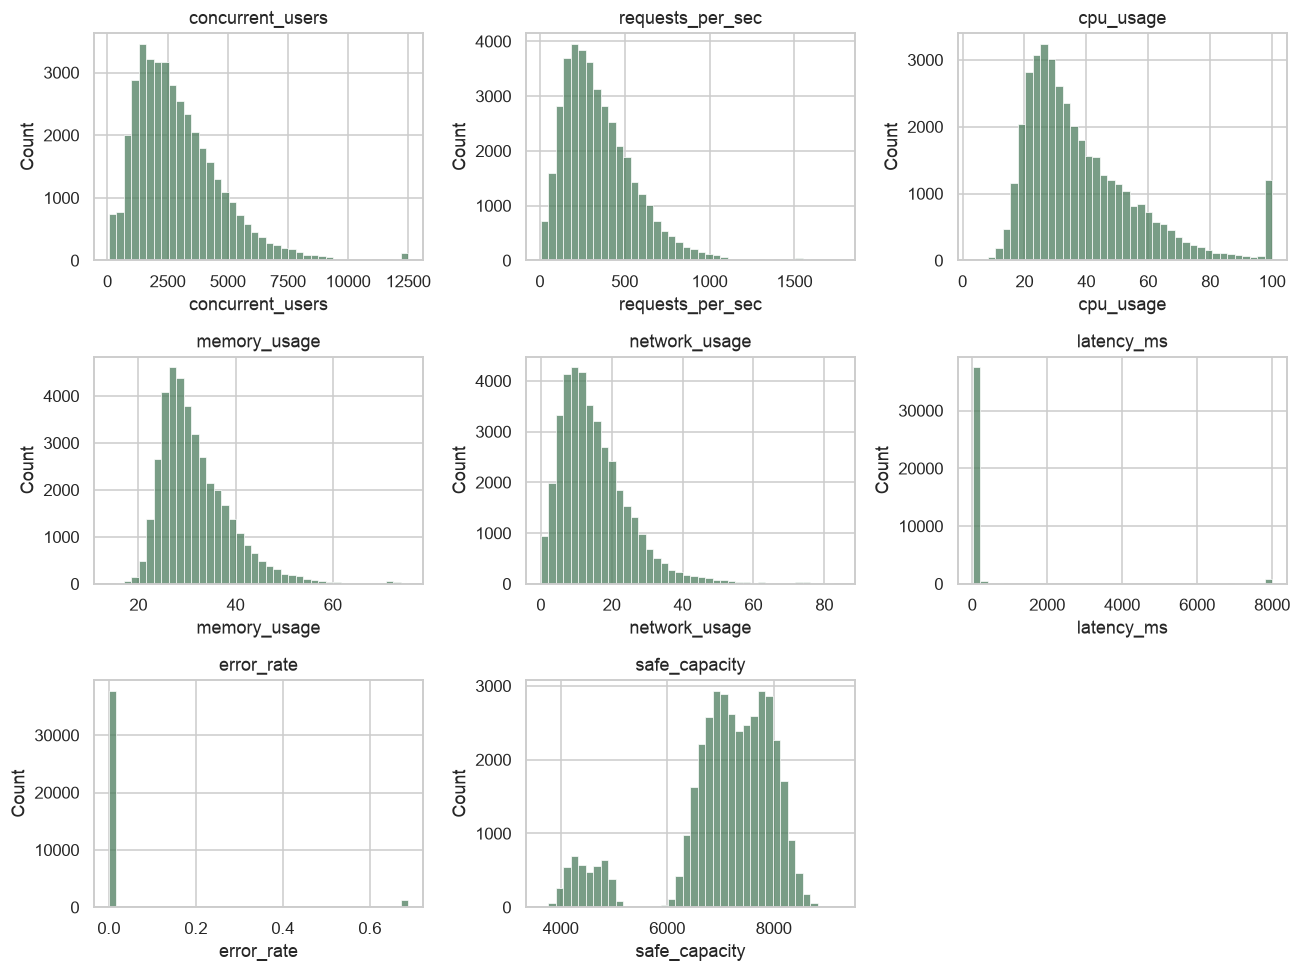

In [6]:
feat = [
    "concurrent_users", "requests_per_sec", "cpu_usage", "memory_usage",
    "network_usage", "latency_ms", "error_rate",
]
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), feat + ["safe_capacity"]):
    sns.histplot(df[col], bins=40, ax=ax, color="#4c7c5d")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
fig.tight_layout()
plt.show()


Notes from the histograms:

- `concurrent_users` and `requests_per_sec` are right-skewed — a few result-window minutes carry extreme load. That is the signal, not a bug.
- `latency_ms` and `error_rate` are *mostly* small, with a long tail. That tail **is** the degradation we need the model to see.
- `memory_usage` moves less than CPU. RAM is a softer constraint in this table.


## 5. The degradation curve (most important plot)

Conceptually we are looking for the knee:

```
latency
  │                 /
  │              __/
  │           __/
  │________ _/
  └──────────────── users
              ↑
        degradation starts
```


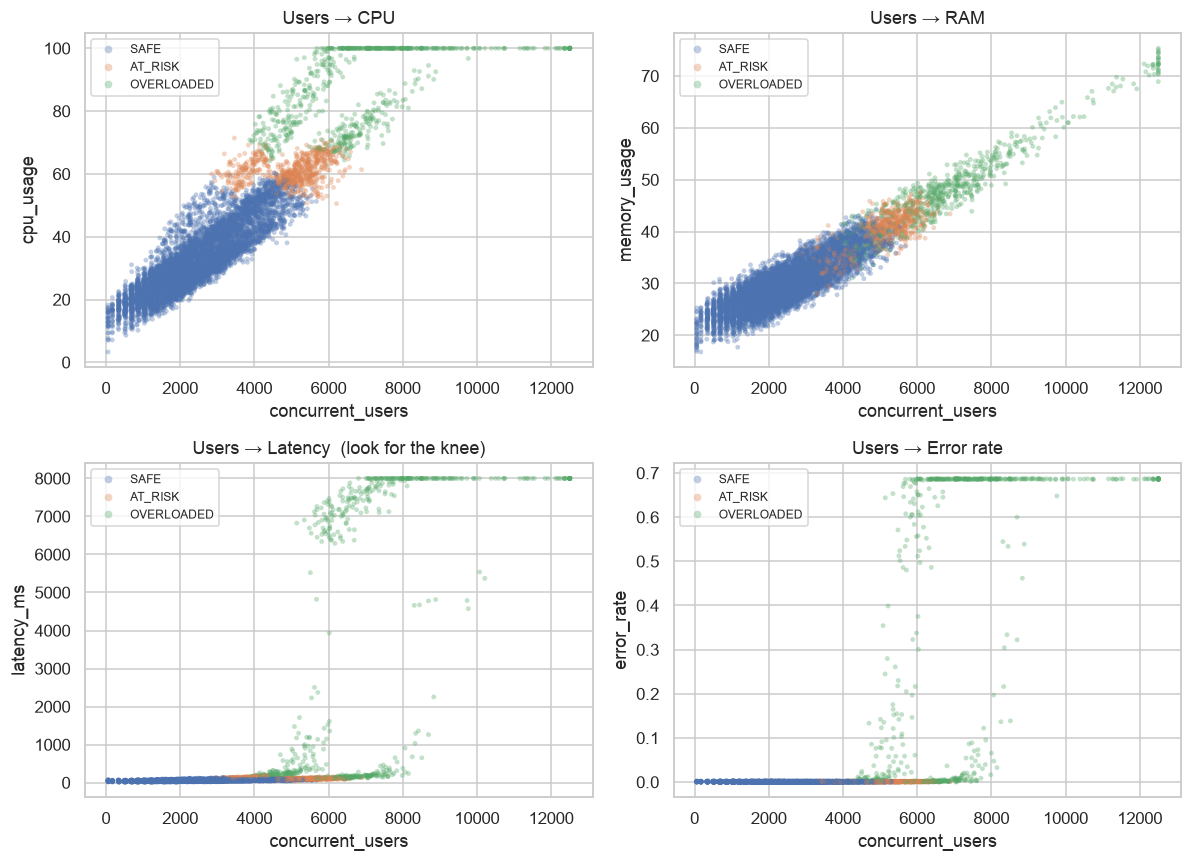

In [7]:
sample = df.sample(min(8000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
pairs = [
    ("concurrent_users", "cpu_usage", "Users → CPU"),
    ("concurrent_users", "memory_usage", "Users → RAM"),
    ("concurrent_users", "latency_ms", "Users → Latency  (look for the knee)"),
    ("concurrent_users", "error_rate", "Users → Error rate"),
]
for ax, (x, y, title) in zip(axes.ravel(), pairs):
    sns.scatterplot(
        data=sample, x=x, y=y, hue="risk_level", hue_order=order,
        s=10, alpha=0.35, ax=ax, edgecolor="none",
    )
    ax.set_title(title)
    ax.legend(markerscale=1.6, fontsize=8)
fig.tight_layout()
plt.show()


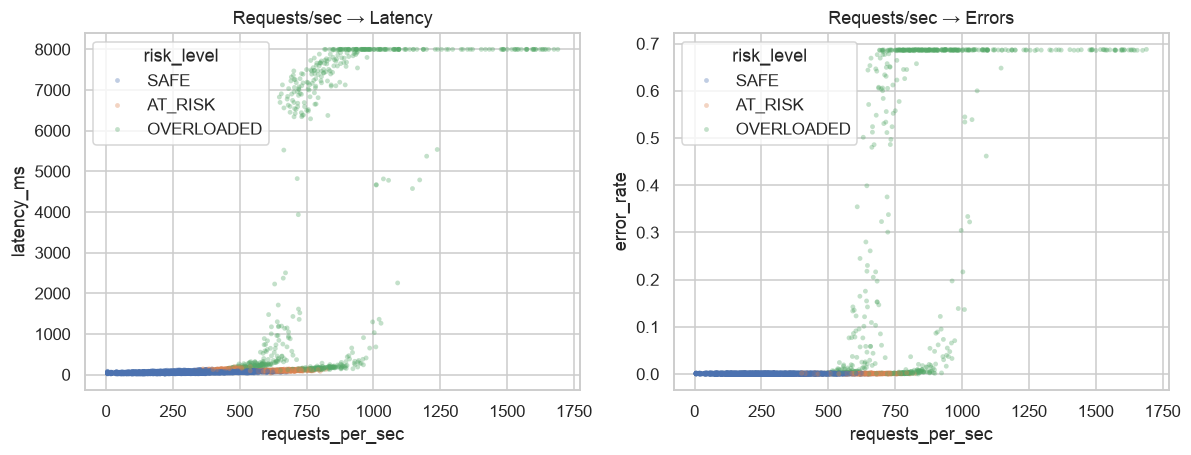

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.scatterplot(
    data=sample, x="requests_per_sec", y="latency_ms",
    hue="risk_level", hue_order=order, s=10, alpha=0.35, ax=axes[0], edgecolor="none",
)
axes[0].set_title("Requests/sec → Latency")
sns.scatterplot(
    data=sample, x="requests_per_sec", y="error_rate",
    hue="risk_level", hue_order=order, s=10, alpha=0.35, ax=axes[1], edgecolor="none",
)
axes[1].set_title("Requests/sec → Errors")
fig.tight_layout()
plt.show()


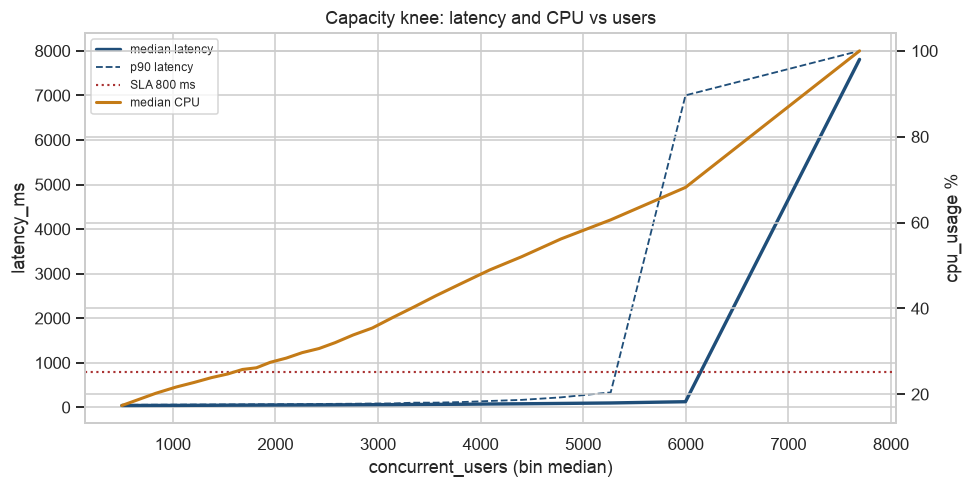

,users,latency,p90_latency,cpu,errors,n
17,3564.0,66.50,104.90,42.940,0.000960,1584
18,3814.0,68.90,118.10,45.820,0.000910,1591
19,4089.0,74.60,142.40,48.960,0.000950,1579
20,4400.5,79.40,166.88,52.040,0.001000,1582
21,4783.5,87.25,223.60,56.180,0.001050,1582
22,5269.0,97.70,335.09,60.635,0.001090,1582
23,5998.0,125.90,7001.54,68.190,0.001440,1583
24,7694.5,7808.40,8000.00,100.000,0.685955,1584


In [9]:
# Binned median curve makes the knee obvious
bins = pd.qcut(df["concurrent_users"], q=25, duplicates="drop")
curve = df.groupby(bins, observed=True).agg(
    users=("concurrent_users", "median"),
    latency=("latency_ms", "median"),
    p90_latency=("latency_ms", lambda s: s.quantile(0.90)),
    cpu=("cpu_usage", "median"),
    errors=("error_rate", "median"),
    n=("concurrent_users", "size"),
).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(9, 4.6))
ax1.plot(curve["users"], curve["latency"], color="#1f4e79", lw=2.2, label="median latency")
ax1.plot(curve["users"], curve["p90_latency"], color="#1f4e79", lw=1.2, ls="--", label="p90 latency")
ax1.axhline(800, color="#a33", ls=":", lw=1.4, label="SLA 800 ms")
ax1.set_xlabel("concurrent_users (bin median)")
ax1.set_ylabel("latency_ms")
ax2 = ax1.twinx()
ax2.plot(curve["users"], curve["cpu"], color="#c47b17", lw=2.0, label="median CPU")
ax2.set_ylabel("cpu_usage %")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax1.set_title("Capacity knee: latency and CPU vs users")
fig.tight_layout()
plt.show()
curve.tail(8)


The scatter is noisy on purpose: the same user count can sit in SAFE or OVERLOADED depending on hidden headroom (background jobs, heavier result-day queries). That is why `safe_capacity` is **not** a trivial function of `concurrent_users`, and why a model has something to learn from the telemetry.


## 6. Correlations — which features actually move together

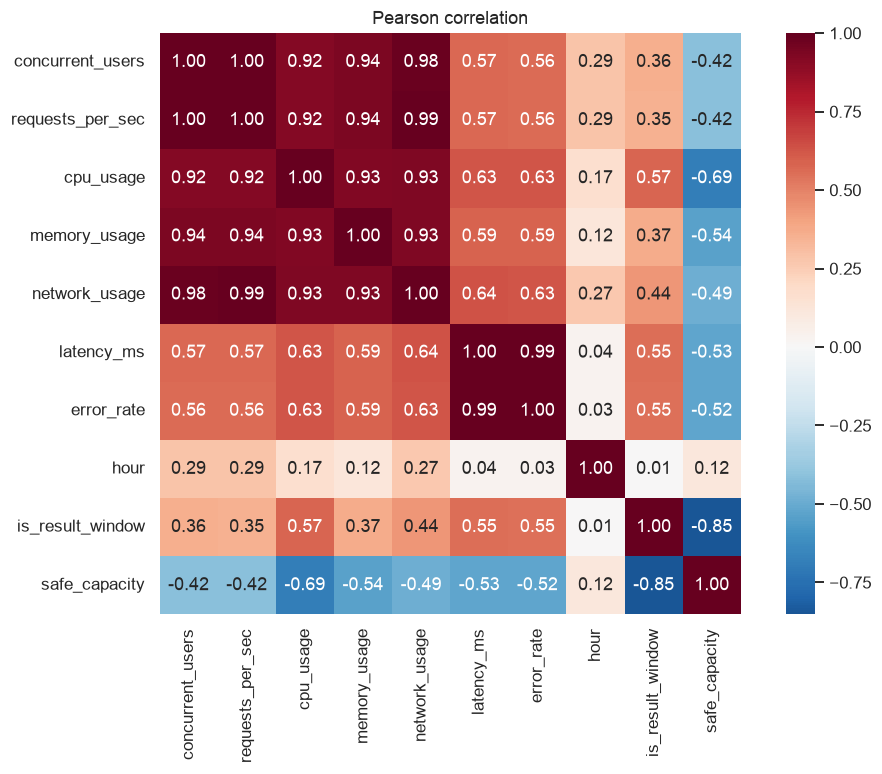

correlation with safe_capacity
is_result_window   -0.852116
cpu_usage          -0.690832
memory_usage       -0.537228
latency_ms         -0.525218
error_rate         -0.521260
network_usage      -0.489095
concurrent_users   -0.416393
requests_per_sec   -0.415707
hour                0.117259
safe_capacity       1.000000
Name: safe_capacity, dtype: float64

correlation with concurrent_users
concurrent_users    1.000000
requests_per_sec    0.998014
network_usage       0.984780
memory_usage        0.937399
cpu_usage           0.917892
latency_ms          0.569692
error_rate          0.563181
is_result_window    0.356608
hour                0.290001
safe_capacity      -0.416393
Name: concurrent_users, dtype: float64


In [10]:
num = [
    "concurrent_users", "requests_per_sec", "cpu_usage", "memory_usage",
    "network_usage", "latency_ms", "error_rate", "hour",
    "is_result_window", "safe_capacity",
]
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, square=True)
ax.set_title("Pearson correlation")
fig.tight_layout()
plt.show()
print("correlation with safe_capacity")
print(corr["safe_capacity"].sort_values())
print()
print("correlation with concurrent_users")
print(corr["concurrent_users"].sort_values(ascending=False))


How to read this for Team 2:

- `concurrent_users` ↔ `requests_per_sec` will be high. They are two views of the same demand. Keep both, but expect multicollinearity in linear models.
- `cpu_usage` tracks users closely. It is the strongest *observable* saturation signal.
- `latency_ms` and `error_rate` correlate more weakly in Pearson terms because the relationship is **nonlinear** (flat, then a knee). Trees / MLP will handle this better than a plain linear regressor.
- `safe_capacity` is *negatively* related to CPU and to `is_result_window`. Result windows have a heavier query mix, so the same hardware holds fewer users.
- Do not interpret a low Pearson of latency vs capacity as “latency is useless.” Look at the knee plot above.


## 7. Calendar and result windows

                  concurrent_users  cpu_usage  latency_ms  error_rate  \
is_result_window                                                        
0                           2447.0      31.46       55.50         0.0   
1                           4202.5      67.32      164.85         0.0   

                  safe_capacity  
is_result_window                 
0                        7352.0  
1                        4473.0  


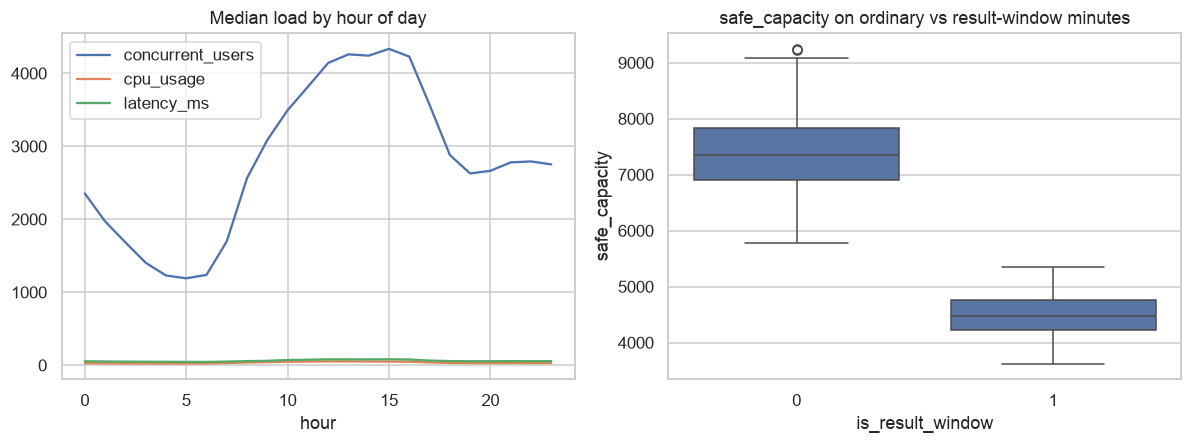

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
hourly = df.groupby("hour")[["concurrent_users", "cpu_usage", "latency_ms"]].median()
hourly.plot(ax=axes[0])
axes[0].set_title("Median load by hour of day")
axes[0].set_xlabel("hour")

by_res = df.groupby("is_result_window")[["concurrent_users", "cpu_usage", "latency_ms", "error_rate", "safe_capacity"]].median()
print(by_res.round(2))
sns.boxplot(data=df, x="is_result_window", y="safe_capacity", ax=axes[1])
axes[1].set_title("safe_capacity on ordinary vs result-window minutes")
fig.tight_layout()
plt.show()


heaviest days
            result   users
day                       
2025-06-21       1  4391.0
2025-06-28       1  4390.0
2025-06-18       0  4132.0
2025-06-27       0  4073.0
2025-06-20       1  3815.0
2025-06-19       0  3384.0
plotting result 2025-06-21 vs ordinary 2025-06-18


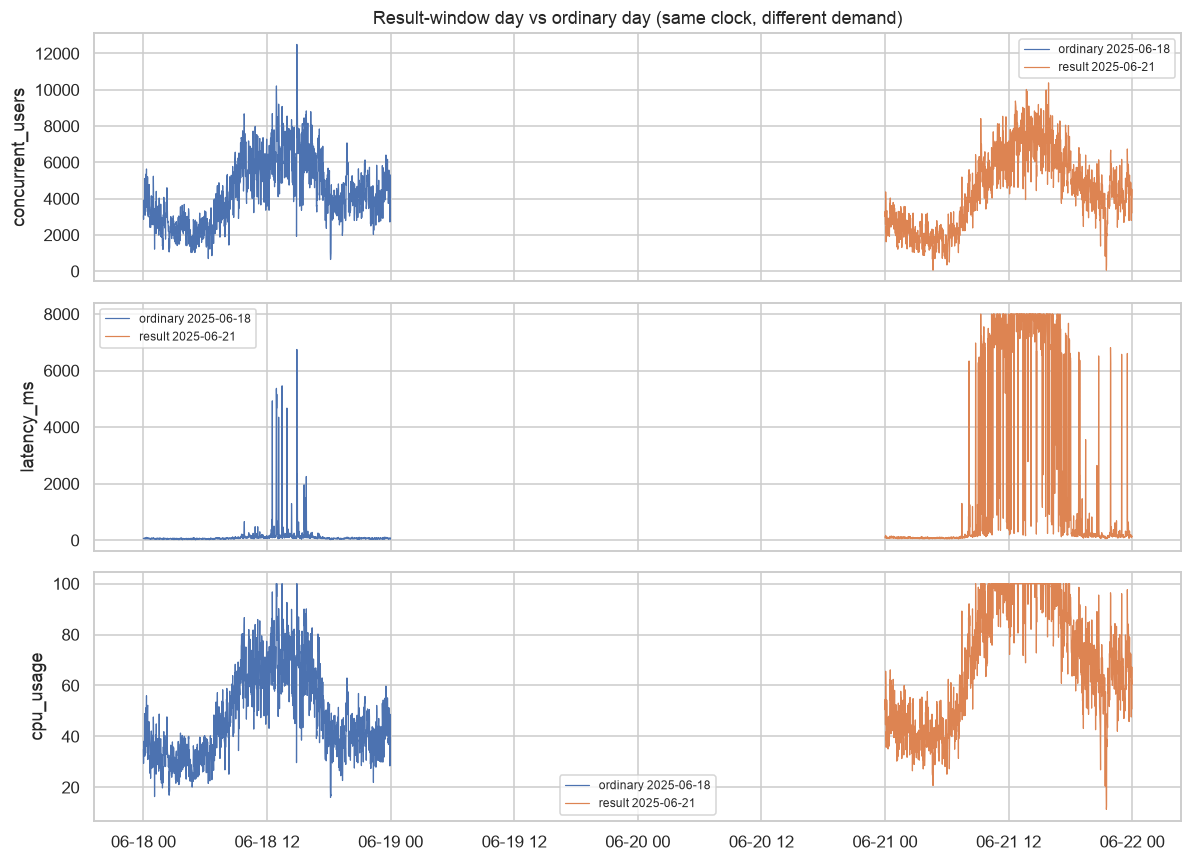

In [12]:
# One result-window day vs a nearby ordinary day
days = (
    df.assign(day=df["timestamp"].dt.date)
    .groupby("day")
    .agg(result=("is_result_window", "max"), users=("concurrent_users", "median"))
    .sort_values("users", ascending=False)
)
print("heaviest days")
print(days.head(6))
result_day = days[days["result"] == 1].index[0]
normal_day = days[days["result"] == 0].index[0]
print("plotting result", result_day, "vs ordinary", normal_day)

sub = df[df["timestamp"].dt.date.isin([result_day, normal_day])].copy()
sub["which"] = np.where(sub["timestamp"].dt.date == result_day, f"result {result_day}", f"ordinary {normal_day}")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, col in zip(axes, ["concurrent_users", "latency_ms", "cpu_usage"]):
    for name, part in sub.groupby("which"):
        ax.plot(part["timestamp"], part[col], lw=0.8, label=name)
    ax.set_ylabel(col)
    ax.legend(fontsize=8)
axes[0].set_title("Result-window day vs ordinary day (same clock, different demand)")
fig.tight_layout()
plt.show()


The diurnal shape is inherited from the **real NASA July 1995 request process** (night trough, late-morning / afternoon peak). Result windows are NASA’s three heaviest calendar days, remapped onto the 2025 observation window. Those days show higher users, higher CPU, higher latency, and **lower** `safe_capacity` — the query mix is heavier, so the SLA ceiling drops.


## 8. Outliers and suspicious rows

In [13]:
print("latency_ms > 2000:", int((df["latency_ms"] > 2000).sum()))
print("error_rate > 0.10:", int((df["error_rate"] > 0.10).sum()))
print("cpu_usage >= 99:", int((df["cpu_usage"] >= 99).sum()))
print("users > safe_capacity:", int((df["concurrent_users"] > df["safe_capacity"]).sum()))
print()
print("These are overload minutes, not sensor bugs. They should stay in the table.")
print()
print(df.nlargest(5, "latency_ms")[
    ["timestamp", "concurrent_users", "requests_per_sec", "cpu_usage", "latency_ms", "error_rate", "safe_capacity", "risk_level", "is_result_window"]
].to_string(index=False))


latency_ms > 2000: 1404
error_rate > 0.10: 1579
cpu_usage >= 99: 1162
users > safe_capacity: 2351

These are overload minutes, not sensor bugs. They should stay in the table.

          timestamp  concurrent_users  requests_per_sec  cpu_usage  latency_ms  error_rate  safe_capacity risk_level  is_result_window
2025-06-20 10:42:00              7452           864.976      100.0      8000.0     0.68579           3856 OVERLOADED                 1
2025-06-20 10:45:00              6807           817.621      100.0      8000.0     0.68592           3769 OVERLOADED                 1
2025-06-20 10:58:00              6931           866.142      100.0      8000.0     0.68748           3765 OVERLOADED                 1
2025-06-20 11:13:00              7337           887.784      100.0      8000.0     0.68610           3911 OVERLOADED                 1
2025-06-20 11:18:00              7149           855.189      100.0      8000.0     0.68561           3957 OVERLOADED                 1


Cleaning already removed the *impossible* values (CPU = 999, negative latency, monitoring dropouts). What remains in the tail is the degradation we want Team 2’s model to predict. Do not drop `latency_ms > 2000` as outliers unless you are deliberately training a “normal-only” model — that would hide result day.


## 9. Does the table support the PortalPulse problem?

In [14]:
util = df["concurrent_users"] / df["safe_capacity"]
print("utilization p50/p90/p99:", util.quantile([0.5, 0.9, 0.99]).round(3).tolist())
print()
print("median telemetry by risk_level")
print(
    df.groupby("risk_level")[["concurrent_users", "cpu_usage", "latency_ms", "error_rate", "safe_capacity"]]
    .median()
    .reindex(["SAFE", "AT_RISK", "OVERLOADED"])
    .round(2)
)


utilization p50/p90/p99: [0.355, 0.831, 2.056]

median telemetry by risk_level
            concurrent_users  cpu_usage  latency_ms  error_rate  safe_capacity
risk_level                                                                    
SAFE                  2264.0      30.40       54.10        0.00         7397.5
AT_RISK               5147.5      60.93      104.90        0.00         6672.0
OVERLOADED            6617.0      85.80      654.65        0.11         4478.0


**Yes — with an explicit caveat.**

| Question | Answer |
|---|---|
| Is there a workload signal? | Yes. Users and RPS follow a real 28-day web-traffic shape (NASA HTTP Jul95). |
| Do server metrics respond to that workload? | Yes. CPU tracks users; latency and errors stay flat then bend (the knee). |
| Can we define a target? | Yes. `safe_capacity` is the max users that still meet SLA (800 ms, 1% errors, 85% CPU) given current hidden headroom. `risk_level` is derived from that. |
| Is this a raw production ERP dump? | No. No public dataset we inspected had traffic **and** CPU/RAM **and** a capacity label. Telemetry and the target are produced by a documented resource + queueing model *driven by the real NASA load*. |
| Should Team 2 split now? | No. Use this one file. Fit any scaler on **train only** after they split. |

Recommended Team 2 starting point:

1. Split `dataset_clean.csv` by time (e.g. last 5 days = test) **or** a stratified random split on `risk_level`. Time split is closer to production.
2. Features = all columns except `timestamp`, `safe_capacity`, `risk_level`.
3. Train a baseline regressor on `safe_capacity` (MAE / RMSE). Derive risk at inference from `current_users / predicted_capacity`.
4. Optionally train a classifier on `risk_level` and compare.


## 10. Leakage checklist for Team 2

- Do **not** use `safe_capacity` as an input feature.
- Do **not** compute `utilization = concurrent_users / safe_capacity` and feed that in — that *is* the answer.
- `risk_level` is a label, not a feature, unless you are predicting the other target.
- `is_result_window` is a legitimate calendar feature (result dates are known in advance). It is not leakage.
- Fit StandardScaler / imputers on the training fold only.
